## Task 1 — Data Processing and Version Alignment

We loaded all seven datasets, including Human and six LLM sources. We normalized the version names and aligned T0 with seven T1 paraphraser variants using `key`, `source`, and `dataset`. After excluding incomplete records and one record containing empty text, we obtained 18,049 complete article-source pairs.

#### Dataset Access

The processed dataset (`paired_all.pkl`, 18,049 aligned pairs) is available on [Google Drive](https://drive.google.com/file/d/19V_df0vA-gSeNCo8XYq3gnv0LH-qM5ln/view?usp=sharing). Download the file and place it in `data/processed/` to run the notebook. Alternatively, the Task 1 preprocessing code can regenerate the file from the original seven CSV datasets.

In [1]:
import pandas as pd
from pathlib import Path

AUDIT_VERSIONS = {
    "original": "text_T0",
    "chatgpt": "text_chatgpt",
    "palm": "text_palm",
    "dipper": "text_dipper",
    "dipper(low)": "text_dipper_low",
    "dipper(high)": "text_dipper_high",
    "pegasus(slight)": "text_pegasus_slight",
    "pegasus(full)": "text_pegasus_full",
}

DATASETS = [
    "xsum", "tldr", "sci_gen", "cmv",
    "wp", "eli5", "yelp",
]


def load_all_datasets(data_dir):
    frames = []

    for name in DATASETS:
        path = Path(data_dir) / f"{name}_paraphrased.csv"
        df = pd.read_csv(path)
        df["dataset"] = name
        frames.append(df)

    return pd.concat(frames, ignore_index=True)


def normalize_versions(df):
    df = df.copy()
    df["version_name"] = df["version_name"].replace(
        {"orignal": "original"}
    )
    return df


def build_paired_dataset(df):
    df = normalize_versions(df)

    temp = df[df["version_name"].isin(AUDIT_VERSIONS)].copy()
    temp["text_column"] = temp["version_name"].map(AUDIT_VERSIONS)

    index_cols = ["key", "source", "dataset"]
    text_cols = list(AUDIT_VERSIONS.values())

    if temp.duplicated(index_cols + ["text_column"]).any():
        raise ValueError("Duplicate article-version records found")

    paired = temp.pivot(
        index=index_cols,
        columns="text_column",
        values="text"
    ).reset_index()

    paired.columns.name = None
    paired = paired.dropna(subset=text_cols).copy()

    valid = paired[text_cols].apply(
        lambda col: col.astype(str).str.strip().ne("")
    ).all(axis=1)

    return paired.loc[
        valid, index_cols + text_cols
    ].reset_index(drop=True)

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

cache_path = PROJECT_ROOT / "data/processed/paired_all.pkl"

if cache_path.exists():
    paired = pd.read_pickle(cache_path)
    print("Loaded cached dataset.")
else:
    raw = load_all_datasets(
        PROJECT_ROOT / "data/raw/paraphrased_datasets"
    )

    paired = build_paired_dataset(raw)

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    paired.to_pickle(cache_path)
    print("Created and cached dataset.")

print("Paired shape:", paired.shape)
print("Datasets:", paired["dataset"].nunique())
print("Sources:", paired["source"].nunique())

Loaded cached dataset.
Paired shape: (18049, 11)
Datasets: 7
Sources: 7


In [3]:
required_cols = [
    "text_T0",
    "text_chatgpt",
    "text_dipper_high",
    "text_pegasus_slight",
]

assert set(required_cols).issubset(paired.columns)
assert paired["dataset"].nunique() == 7
assert not paired.duplicated(["key", "source", "dataset"]).any()
assert paired[required_cols].notna().all().all()

print("Task 1 validation passed.")

Task 1 validation passed.


In [4]:
pd.crosstab(paired["dataset"], paired["source"])

source,BigScience,Eleuther-AI,Human,LLAMA,OpenAI,PaLM,Tsinghua
dataset,,,,,,,
cmv,227,184,231,239,239,162,233
eli5,442,363,454,450,461,469,455
sci_gen,351,184,438,446,468,449,389
tldr,355,302,377,360,378,254,367
wp,333,227,269,324,434,94,327
xsum,462,416,342,464,460,438,456
yelp,452,445,486,480,472,473,468


**Note:** Task 1 requires T0 and three T1 paraphraser variants. We include all seven T1 variants to support the later analyses using a consistent set of articles. All four required text columns are included.

In [5]:
samples = paired.groupby("dataset").head(2).copy()

text_cols = [c for c in paired.columns if c.startswith("text_")]

for col in text_cols:
    samples[col] = samples[col].str.slice(0, 80)

display(samples)

,key,source,dataset,text_T0,text_chatgpt,text_palm,text_dipper,text_dipper_low,text_dipper_high,text_pegasus_slight,text_pegasus_full
0,cmv-1079,BigScience,cmv,Please note before reading: Please do not down...,Please be aware that I kindly request not to d...,expressions with Java 8 Stream API The followi...,Before you read any further: I have written a...,Please note before reading: Do not downvote m...,A style of camouflaging the impossible became...,Please note before reading: Please do not down...,Please don't downvote my comments and replies ...
1,cmv-1079,Eleuther-AI,cmv,Please note before reading: Please do not down...,I kindly request that you refrain from downvot...,"**Note:** Before reading, please keep in mind ...","NB: The first time I tried this out, it was b...",Please note before reading: Please do not dow...,"Remember once again I say, downvoting is not ...",Please don't downvote my comments and replies ...,Please don't downvote my comments and replies ...
1515,eli5-16706,BigScience,eli5,It's your body that is preparing to fight for ...,"When faced with a threatening situation, your ...","When confronted with a threatening situation, ...",Because the brain takes it for a threat. Adre...,Because your brain perceives it as a threat. ...,They had gone to watch—a perilous walk—from L...,It's your body that is preparing to fight for ...,"If you see something threatening, your body is..."
1516,eli5-16706,Eleuther-AI,eli5,It's your body that is preparing to fight for ...,When your brain perceives something threatenin...,"When you see something threatening, your body ...","Since the brain takes in the threat, it begin...",Because your brain takes it as a threat. It i...,You must have foreseen some dreadful monster ...,It's your body that is preparing to fight for ...,"If you see something threatening, your body is..."
4609,sci_gen-1744,BigScience,sci_gen,"In this article, we investigate the transient ...",This article explores the behavior of packetsb...,"P: [t 2, t] R will belong to this class. This ...",- It is usually called a factory network. We ...,"In this article, we investigate the transient...",These were three years of great difficulty. T...,"In this article, we investigate the transient ...",Transient behavior of packetsbits traversing a...
4610,sci_gen-1744,Human,sci_gen,"In this article, we investigate whispered-to n...",This article examines a method for converting ...,This paper proposes a modified transformer arc...,It is with this in mind that we propose to in...,"In this article, we investigate a whisper-to-...",Gulathy blew two pitcherfuls of tea for himse...,"In this article, we investigate whispered-to n...",We investigated whispered-to natural-speech co...
7334,tldr-2826,BigScience,tldr,Tensorflow Privacy implements Tensorflow optim...,Tensorflow Privacy is a library that enables t...,information useful for inferring sensitive att...,The author's contribution to the science is a...,Contribution to the research field: TensorFlo...,The next morning we went down to the little t...,Machine learning models with differential priv...,Machine learning models with differential priv...
7335,tldr-2826,Eleuther-AI,tldr,Tensorflow Privacy implements Tensorflow optim...,Tensorflow Privacy provides Tensorflow optimiz...,TensorFlow Privacy provides optimizers for tra...,TensorFlow's privacy group develops a tensorf...,TensorFlow privacy is an implementation of Te...,There was a chance of seeing Amsden's line in...,Machine learning models with differential priv...,Machine learning models with differential priv...
9727,wp-1198,BigScience,wp,"""and those are the terms. I'm sorry."" The Athe...","""Those are the terms, and I apologize,"" said t...",", only 20% of women have access to managerial ...","The Atheist, a young hippie girl in thick gla...","The atheist, a young female hipster in thick-...",Atheism pressed her with even greater persuas...,"""and those are the terms. I'm sorry. The Athei...","Those are the te

## Task 2 — POS Tagging & Stylistic Drift

We compare the normalized POS distributions of T0 texts with their T1
versions produced by ChatGPT and Dipper(high), across all seven datasets.

### 2a. POS Extraction

Using spaCy's `en_core_web_sm` model, each text is represented by a
17-dimensional Universal POS (UPOS) vector. Counts are divided by the total
number of non-space tokens so texts of different lengths remain comparable.
The extraction is applied to `text_T0`, `text_chatgpt`, and
`text_dipper_high` for every paired article.

In [6]:
import hashlib
import json
import warnings

warnings.filterwarnings(
    "ignore", message="urllib3 v2 only supports OpenSSL.*"
)

import matplotlib.pyplot as plt
import numpy as np
import spacy

paired = paired.reset_index(drop=True)
required_text_columns = ["text_T0", "text_chatgpt", "text_dipper_high"]

for column in required_text_columns:
    assert paired[column].map(
        lambda text: isinstance(text, str) and bool(text.strip())
    ).all(), f"Missing or empty text in {column}"

nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner", "lemmatizer"],
)

output_dir = PROJECT_ROOT / "data" / "results" / "task2_pos"
cache_root = PROJECT_ROOT / "data" / "cache" / "task2_pos"
output_dir.mkdir(parents=True, exist_ok=True)
cache_root.mkdir(parents=True, exist_ok=True)

print(f"Paired records: {len(paired):,}")
print(f"spaCy: {spacy.__version__}; model: {nlp.meta['version']}")

Paired records: 18,049
spaCy: 3.7.5; model: 3.7.1


In [7]:
UPOS = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET",
    "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN",
    "PUNCT", "SCONJ", "SYM", "VERB", "X",
]
TAG_INDEX = {tag: i for i, tag in enumerate(UPOS)}


def pos_vector(doc):
    # Return a normalized 17-tag UPOS vector for one spaCy Doc.
    counts = np.zeros(len(UPOS), dtype=float)

    for token in doc:
        if token.is_space:
            continue
        if token.pos_ not in TAG_INDEX:
            raise ValueError(f"Unexpected POS tag: {token.pos_!r}")
        counts[TAG_INDEX[token.pos_]] += 1

    total = counts.sum()
    if total == 0:
        raise ValueError("Text contains no non-space tokens")

    return counts / total


test_vector = pos_vector(nlp("This is a test."))
assert test_vector.shape == (17,)
assert np.isclose(test_vector.sum(), 1.0)
print("POS vector validation passed: 17 tags, proportions sum to 1.")

POS vector validation passed: 17 tags, proportions sum to 1.


In [8]:
text_hash = hashlib.sha256(
    pd.util.hash_pandas_object(
        paired[required_text_columns], index=True
    ).values.tobytes()
).hexdigest()

cache_settings = {
    "text_hash": text_hash,
    "spacy_version": spacy.__version__,
    "model_version": nlp.meta["version"],
    "tags": UPOS,
}
cache_id = hashlib.sha256(
    json.dumps(cache_settings, sort_keys=True).encode()
).hexdigest()[:16]

# Caches are reproducible intermediate files, so they live outside results/.
cache_dir = cache_root / f"spacy-{nlp.meta['version']}-{cache_id}"
cache_dir.mkdir(parents=True, exist_ok=True)

print("POS cache:", cache_dir.relative_to(PROJECT_ROOT))

POS cache: data/cache/task2_pos/spacy-3.7.1-60646b4e3547511d


In [9]:
def extract_pos(column):
    # Extract POS vectors for one text column, reusing a valid cache.
    cache_path = cache_dir / f"{column}.npy"

    if cache_path.exists():
        matrix = np.load(cache_path)
        if matrix.shape == (len(paired), len(UPOS)):
            print(f"Loaded cache: {column}")
            return matrix
        print(f"Ignoring invalid cache shape for {column}: {matrix.shape}")

    rows = []
    for i, doc in enumerate(
        nlp.pipe(paired[column], batch_size=64), start=1
    ):
        rows.append(pos_vector(doc))
        if i % 2000 == 0:
            print(f"{column}: {i:,}/{len(paired):,}", flush=True)

    matrix = np.vstack(rows)
    np.save(cache_path, matrix)
    print(f"{column}: complete")
    return matrix

In [10]:
pos_T0 = extract_pos("text_T0")
pos_chatgpt = extract_pos("text_chatgpt")
pos_dipper_high = extract_pos("text_dipper_high")

pos_matrices = {
    "T0": pos_T0,
    "chatgpt": pos_chatgpt,
    "dipper_high": pos_dipper_high,
}

for name, matrix in pos_matrices.items():
    assert matrix.shape == (len(paired), 17)
    assert np.isfinite(matrix).all()
    assert np.allclose(matrix.sum(axis=1), 1.0)
    paired[f"pos_{name}"] = list(matrix)

print("POS extraction completed and validated for all three versions.")

Loaded cache: text_T0
Loaded cache: text_chatgpt
Loaded cache: text_dipper_high
POS extraction completed and validated for all three versions.


### 2b. POS Cosine Similarity

Cosine similarity is calculated between each article's T0 POS vector and its
ChatGPT and Dipper(high) T1 vectors. Lower similarity indicates greater
stylistic drift. Results are reported as mean ± sample standard deviation,
both overall and separately for every dataset.

In [11]:
def row_cosine(a, b):
    numerator = np.einsum("ij,ij->i", a, b)
    denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    assert (denominator > 0).all()
    return np.clip(numerator / denominator, -1, 1)


scores = paired[["key", "source", "dataset"]].copy()
scores["chatgpt"] = row_cosine(pos_T0, pos_chatgpt)
scores["dipper_high"] = row_cosine(pos_T0, pos_dipper_high)

long_scores = scores.melt(
    id_vars=["key", "source", "dataset"],
    value_vars=["chatgpt", "dipper_high"],
    var_name="paraphraser",
    value_name="cosine_similarity",
)

display(scores.head())

,key,source,dataset,chatgpt,dipper_high
0,cmv-1079,BigScience,cmv,0.997448,0.907720
1,cmv-1079,Eleuther-AI,cmv,0.966492,0.916016
2,cmv-1079,Human,cmv,0.960989,0.951403
3,cmv-1079,LLAMA,cmv,0.986671,0.945779
4,cmv-1079,OpenAI,cmv,0.973857,0.842008


In [12]:
def formatted_summary(table):
    result = table.copy()
    result["mean ± std"] = result.apply(
        lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}",
        axis=1,
    )
    return result[["count", "mean ± std"]]


overall_summary = (
    long_scores
    .groupby("paraphraser")["cosine_similarity"]
    .agg(["count", "mean", "std"])
)

dataset_summary = (
    long_scores
    .groupby(["dataset", "paraphraser"])["cosine_similarity"]
    .agg(["count", "mean", "std"])
)

print("Overall POS cosine similarity:")
display(formatted_summary(overall_summary))
print("POS cosine similarity by dataset:")
display(formatted_summary(dataset_summary))

Overall POS cosine similarity:


,count,mean ± std
paraphraser,,
chatgpt,18049,0.9686 ± 0.0381
dipper_high,18049,0.8784 ± 0.0904


POS cosine similarity by dataset:


count       mean ± std
dataset paraphraser                        
cmv     chatgpt       1515  0.9718 ± 0.0254
        dipper_high   1515  0.9129 ± 0.0638
eli5    chatgpt       3094  0.9596 ± 0.0426
        dipper_high   3094  0.8842 ± 0.0915
sci_gen chatgpt       2725  0.9776 ± 0.0436
        dipper_high   2725  0.8544 ± 0.0922
tldr    chatgpt       2393  0.9745 ± 0.0225
        dipper_high   2393  0.8557 ± 0.0929
wp      chatgpt       2008  0.9650 ± 0.0471
        dipper_high   2008  0.9277 ± 0.0635
xsum    chatgpt       3038  0.9721 ± 0.0284
        dipper_high   3038  0.8591 ± 0.0961
yelp    chatgpt       3276  0.9628 ± 0.0414
        dipper_high   3276  0.8810 ± 0.0868

### 2c. Human vs. LLM Sources

Human originals are identified by `source == 'Human'`; every other source is
grouped as LLM. We first compute Human and LLM means within each of the seven
datasets, then give each dataset equal weight in the aggregate comparison.

In [13]:
long_scores["source_group"] = np.where(
    long_scores["source"].eq("Human"), "Human", "LLM"
)

source_summary = (
    long_scores
    .groupby(
        ["dataset", "paraphraser", "source_group"]
    )["cosine_similarity"]
    .agg(["count", "mean", "std"])
)
assert len(source_summary) == 28
assert (source_summary["count"] > 0).all()

balanced_summary = (
    source_summary["mean"]
    .groupby(["paraphraser", "source_group"])
    .agg(["count", "mean", "std"])
)

group_means = source_summary["mean"].unstack("source_group")
human_lower_counts = (
    (group_means["Human"] < group_means["LLM"])
    .groupby("paraphraser")
    .sum()
)

print("Human vs. LLM within each dataset:")
display(formatted_summary(source_summary))
print("Equal-weight aggregate across seven dataset means:")
display(formatted_summary(balanced_summary))
print("Datasets where Human similarity is lower:")
display(human_lower_counts)

Human vs. LLM within each dataset:


count       mean ± std
dataset paraphraser source_group                        
cmv     chatgpt     Human           231  0.9779 ± 0.0179
                    LLM            1284  0.9707 ± 0.0264
        dipper_high Human           231  0.9469 ± 0.0374
                    LLM            1284  0.9068 ± 0.0656
eli5    chatgpt     Human           454  0.9628 ± 0.0353
                    LLM            2640  0.9591 ± 0.0438
        dipper_high Human           454  0.8999 ± 0.0808
                    LLM            2640  0.8815 ± 0.0930
sci_gen chatgpt     Human           438  0.9891 ± 0.0078
                    LLM            2287  0.9754 ± 0.0471
        dipper_high Human           438  0.8468 ± 0.0997
                    LLM            2287  0.8559 ± 0.0906
tldr    chatgpt     Human           377  0.9747 ± 0.0182
                    LLM            2016  0.9745 ± 0.0232
        dipper_high Human           377  0.8377 ± 0.0865
                    LLM            2016  0.8591 ± 0.0937
wp      chatgpt     Human           269  0.9833 ± 0.0207
                    LLM            1739  0.9621 ± 0.0494
        dipper_high Human           269  0.9567 ± 0.0411
                    LLM            1739  0.9232 ± 0.0652
xsum    chatgpt     Human           342  0.9778 ± 0.0360
                    LLM            2696  0.9714 ± 0.0272
        dipper_high Human           342  0.8794 ± 0.0866
                    LLM            2696  0.8565 ± 0.0970
yelp    chatgpt     Human           486  0.9557 ± 0.0516
                    LLM            2790  0.9640 ± 0.0393
        dipper_high Human           486  0.8716 ± 0.0960
                    LLM            2790  0.8827 ± 0.0850

Equal-weight aggregate across seven dataset means:


count       mean ± std
paraphraser source_group                        
chatgpt     Human             7  0.9745 ± 0.0116
            LLM               7  0.9682 ± 0.0064
dipper_high Human             7  0.8913 ± 0.0462
            LLM               7  0.8808 ± 0.0263

Datasets where Human similarity is lower:


paraphraser
chatgpt        1
dipper_high    3
dtype: int64

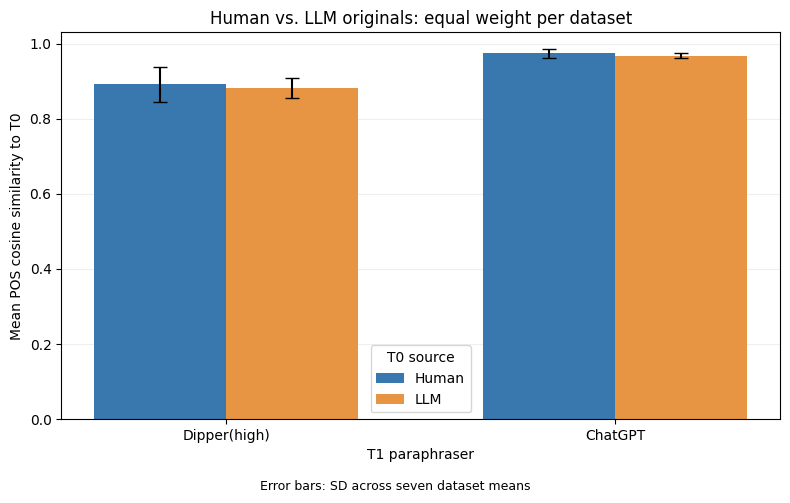

In [14]:
order = ["dipper_high", "chatgpt"]
x = np.arange(len(order))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

for group, offset, color in [
    ("Human", -width / 2, "#3978af"),
    ("LLM", width / 2, "#e79543"),
]:
    values = balanced_summary.xs(
        group, level="source_group"
    ).reindex(order)

    ax.bar(
        x + offset,
        values["mean"],
        width,
        yerr=values["std"],
        capsize=5,
        label=group,
        color=color,
    )

ax.set_xticks(x, ["Dipper(high)", "ChatGPT"])
ax.set_xlabel("T1 paraphraser")
ax.set_ylabel("Mean POS cosine similarity to T0")
ax.set_title("Human vs. LLM originals: equal weight per dataset")
ax.set_ylim(0, 1.03)
ax.legend(title="T0 source")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5,
    0.01,
    "Error bars: SD across seven dataset means",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.savefig(
    output_dir / "human_llm_pos_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

In [15]:
scores.to_csv(output_dir / "article_pos_cosines.csv", index=False)
overall_summary.to_csv(output_dir / "overall_pos_summary.csv")
dataset_summary.to_csv(output_dir / "dataset_pos_summary.csv")
source_summary.to_csv(output_dir / "dataset_source_pos_summary.csv")
balanced_summary.to_csv(output_dir / "balanced_source_pos_summary.csv")

print("Task 2 tables and chart saved to:", output_dir.relative_to(PROJECT_ROOT))

Task 2 tables and chart saved to: data/results/task2_pos


### Interpretation

Overall, the POS distribution did not shift more for Human originals. When each dataset was given equal weight, Dipper(high) had a cosine similarity of 0.8913 for Human texts and 0.8808 for LLM texts. ChatGPT showed the same pattern, with 0.9745 for Human texts and 0.9682 for LLM texts. Because lower cosine similarity means greater POS drift, LLM originals changed slightly more overall. However, the pattern was not consistent across every dataset: Human texts showed more drift in 3 of 7 datasets for Dipper and 1 of 7 for ChatGPT. I originally expected LLM texts to change less because they already follow common AI writing patterns. One possible explanation is that different language models have different grammatical preferences, so one model can still noticeably change text produced by another model.

## Task 3 — NER Stability & Content Erasure
We use spaCy’s en_core_web_sm model to extract named entities and measure entity retention, introduction, and content erasure across paraphrasers. We also compare Pegasus(slight) and Pegasus(full) to examine the effect of paraphrasing intensity.

### 3a. NER extraction

Extract entity surface strings from `text_T0`, `text_chatgpt`, `text_dipper_high`, `text_pegasus_slight`, and `text_pegasus_full` using spaCy `en_core_web_sm`. Include all entity labels, lowercase and strip each string, then deduplicate. Repeated mentions count once.

In [16]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import spacy
from IPython.display import Markdown, display

if 'PROJECT_ROOT' not in globals():
    PROJECT_ROOT = Path.cwd().resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent
ner_data_path = PROJECT_ROOT / 'data/processed/paired_all.pkl'
ner_paired = (paired.copy() if 'paired' in globals()
              else pd.read_pickle(ner_data_path)).reset_index(drop=True)
ner_ids = ['dataset', 'key', 'source']
ner_variants = {
    'ChatGPT': 'text_chatgpt',
    'Dipper(high)': 'text_dipper_high',
    'Pegasus(slight)': 'text_pegasus_slight',
    'Pegasus(full)': 'text_pegasus_full',
}
ner_columns = ['text_T0', *ner_variants.values()]
if not set(ner_ids + ner_columns).issubset(ner_paired.columns):
    raise ValueError('Task 1 data must include T0 and all four T1 columns, including pegasus(full).')
if ner_paired.empty or ner_paired[ner_ids].isna().any().any() or ner_paired.duplicated(ner_ids).any():
    raise ValueError('Invalid or duplicate article-source identities.')
for column in ner_columns:
    if not ner_paired[column].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
        raise ValueError(f'Missing or empty text: {column}')
if ner_paired.dataset.nunique() != 7:
    raise ValueError('Expected all seven datasets.')

ner_nlp = spacy.load('en_core_web_sm', disable=['parser', 'lemmatizer', 'tagger', 'attribute_ruler'])
ner_nlp.max_length = max(ner_nlp.max_length,
    int(ner_paired[ner_columns].apply(lambda col: col.str.len().max()).max()) + 1)
ner_texts = list(dict.fromkeys(text for column in ner_columns for text in ner_paired[column]))
NER_USE_CACHE = globals().get('NER_USE_CACHE', True)
NER_PROCESSES = globals().get('NER_PROCESSES', 1) 
ner_fingerprint = hashlib.sha256(json.dumps({
    'texts': ner_texts, 'spacy': spacy.__version__, 'model': ner_nlp.meta,
}, sort_keys=True).encode()).hexdigest()
ner_cache = PROJECT_ROOT / 'data/cache/task3_ner' / f'{ner_fingerprint}.json'
if NER_USE_CACHE and ner_cache.exists():
    ner_entities = {text: set(values) for text, values in json.loads(ner_cache.read_text()).items()}
    if not all(text in ner_entities for text in ner_texts):
        raise ValueError('Incomplete entity cache; delete the cache and rerun.')
    print(f'Loaded matching entity cache for {len(ner_texts):,} unique texts.')
else:
    ner_entities = {}
    docs = ner_nlp.pipe(ner_texts, batch_size=64, n_process=NER_PROCESSES)
    for index, (text, doc) in enumerate(zip(ner_texts, docs), start=1):
        ner_entities[text] = {entity.text.strip().lower() for entity in doc.ents if entity.text.strip()}
        if index % 2000 == 0:
            print(f'NER: {index:,}/{len(ner_texts):,} unique texts', flush=True)
    if NER_USE_CACHE:
        ner_cache.parent.mkdir(parents=True, exist_ok=True)
        ner_cache.write_text(json.dumps({text: sorted(values) for text, values in ner_entities.items()},
                                       ensure_ascii=False))
print(f'Extracted entity sets for {len(ner_paired):,} pairs, five text versions and seven datasets.')
ner_entity_examples = ner_paired[ner_ids].head(2).copy()
for column in ner_columns:
    ner_entity_examples[column + '_entities'] = ner_paired[column].head(2).map(
        lambda text: sorted(ner_entities[text]))
display(ner_entity_examples)


Loaded matching entity cache for 89,341 unique texts.
Extracted entity sets for 18,049 pairs, five text versions and seven datasets.


,dataset,key,source,text_T0_entities,text_chatgpt_entities,text_dipper_high_entities,text_pegasus_slight_entities,text_pegasus_full_entities
0,cmv,cmv-1079,BigScience,"[0, 1.1.7, 10, 16, 2., 3, 9, abstractbutton, a...","[0, 1.1.7, 10, 9, abstractbutton, acl, ai, ann...","[africa, african, asia, cadboro, central and s...","[0, 10, 16, 2., 3, 9, abstractbutton, access c...","[16, 2, 3, about 10, anyenum, c17, cc, cmv, co..."
1,cmv,cmv-1079,Eleuther-AI,"[0, 01, age 47 34, cmv, table 1, two]","[0.01, average exercisers, gender (male/female...","[these quarters, ‘how many days a week should ...","[0, 01, age 47 34, cmv, table 1, two]",[cmv]


### 3b. Entity retention metrics

For each article-source pair and T1 variant, let A be the T0 entity set and B the T1 entity set:

- Jaccard = |A ∩ B| / |A ∪ B|: overall entity-set overlap.
- Recall = |A ∩ B| / |A|: original entity retention; low recall indicates dropping.
- Precision = |A ∩ B| / |B|: fidelity to original entity strings; low precision indicates new entity strings, a proxy for hallucination.

#### Excluded articles

1,600 of 18,049 article-source pairs (8.86%) have zero T0 entities. All three metrics are NaN for these pairs, which are excluded from every metric mean. This leaves 16,449 eligible pairs per variant for Jaccard and recall. For nonempty T0 and empty T1, Jaccard and recall are 0; precision is undefined and excluded separately.

In [17]:
ner_metrics = ['jaccard', 'recall', 'precision']


def entity_retention_metrics(original, rewritten):
    if not original:
        return {metric: np.nan for metric in ner_metrics}
    overlap = len(original & rewritten)
    return {
        'jaccard': overlap / len(original | rewritten),
        'recall': overlap / len(original),
        'precision': overlap / len(rewritten) if rewritten else np.nan,
    }


assert entity_retention_metrics({'alice', 'paris'}, {'paris', 'london'}) == {
    'jaccard': 1 / 3, 'recall': .5, 'precision': .5}
assert all(np.isnan(value) for value in entity_retention_metrics(set(), set()).values())
assert all(np.isnan(value) for value in entity_retention_metrics(set(), {'alice'}).values())
empty_rewrite_check = entity_retention_metrics({'alice'}, set())
assert empty_rewrite_check['jaccard'] == empty_rewrite_check['recall'] == 0
assert np.isnan(empty_rewrite_check['precision'])

ner_rows = []
for record in ner_paired.to_dict('records'):
    original = ner_entities[record['text_T0']]
    for variant, column in ner_variants.items():
        rewritten = ner_entities[record[column]]
        ner_rows.append({
            **{key: record[key] for key in ner_ids}, 'variant': variant,
            'original_entities': json.dumps(sorted(original), ensure_ascii=False),
            'rewritten_entities': json.dumps(sorted(rewritten), ensure_ascii=False),
            'n_original': len(original), 'n_rewritten': len(rewritten),
            'n_retained': len(original & rewritten),
            'n_erased': len(original - rewritten), 'n_added': len(rewritten - original),
            **entity_retention_metrics(original, rewritten),
        })
ner_scores = pd.DataFrame(ner_rows)
assert len(ner_scores) == len(ner_paired) * len(ner_variants)
assert ner_scores.loc[ner_scores.n_original.eq(0), ner_metrics].isna().all().all()


def summarize_entity_scores(scores, groups):
    summary = scores.groupby(groups, sort=True)[ner_metrics].agg(['count', 'mean', 'std']).reset_index()
    summary.columns = ['_'.join(str(part) for part in column if part) for column in summary.columns]
    return summary


ner_overall_summary = summarize_entity_scores(ner_scores, ['variant'])
ner_dataset_summary = summarize_entity_scores(ner_scores, ['dataset', 'variant'])
ner_source_summary = summarize_entity_scores(ner_scores, ['dataset', 'source', 'variant'])
ner_nonempty_summary = summarize_entity_scores(ner_scores[ner_scores.n_original.gt(0)], ['dataset', 'variant'])
pd.testing.assert_frame_equal(ner_nonempty_summary, ner_dataset_summary)
ner_zero_counts = ner_scores.groupby(['dataset', 'variant']).agg(
    n=('key', 'size'), zero_original=('n_original', lambda values: int(values.eq(0).sum())),
    zero_rewritten=('n_rewritten', lambda values: int(values.eq(0).sum()))).reset_index()
ner_excluded = sum(not ner_entities[text] for text in ner_paired.text_T0)
ner_exclusion_markdown = (
    '#### Excluded articles\n\n'
    f'{ner_excluded:,} of {len(ner_paired):,} article-source pairs ({ner_excluded / len(ner_paired):.2%}) '
    'have zero T0 entities. All three metrics are NaN and these pairs are excluded from every mean. '
    f'This leaves {len(ner_paired) - ner_excluded:,} eligible pairs per variant for Jaccard and Recall. '
    'Precision additionally excludes empty T1 entity sets. Standard deviations use ddof=1; '
    'the valid sample count is shown for each metric.'
)
display(Markdown(ner_exclusion_markdown))


def entity_summary_markdown(summary, keys):
    lines = ['| ' + ' | '.join(keys + [metric + ' (n)' for metric in ner_metrics]) + ' |',
             '| ' + ' | '.join(['---'] * (len(keys) + 3)) + ' |']
    for _, row in summary.iterrows():
        values = [str(row[key]) for key in keys]
        values += [f"{row[metric + '_mean']:.3f} ± {row[metric + '_std']:.3f} "
                   f"({int(row[metric + '_count'])})" for metric in ner_metrics]
        lines.append('| ' + ' | '.join(values) + ' |')
    return '\n'.join(lines)


ner_tables_markdown = '#### Comparison tables (mean ± sample SD)\n\n'
ner_tables_markdown += entity_summary_markdown(ner_overall_summary, ['variant']) + '\n\n'
ner_tables_markdown += entity_summary_markdown(ner_dataset_summary, ['dataset', 'variant'])
display(Markdown(ner_tables_markdown))
ner_output = PROJECT_ROOT / 'data/results/task3_ner'
ner_output.mkdir(parents=True, exist_ok=True)
for filename, frame in {
    'article_ner_scores.csv': ner_scores,
    'overall_ner_summary.csv': ner_overall_summary,
    'dataset_ner_summary.csv': ner_dataset_summary,
    'dataset_source_ner_summary.csv': ner_source_summary,
    'nonempty_original_ner_summary.csv': ner_nonempty_summary,
    'zero_entity_counts.csv': ner_zero_counts,
}.items():
    frame.to_csv(ner_output / filename, index=False)
print('Four edge-case checks passed; all tables computed from the entity sets in 3a.')


#### Excluded articles

1,600 of 18,049 article-source pairs (8.86%) have zero T0 entities. All three metrics are NaN and these pairs are excluded from every mean. This leaves 16,449 eligible pairs per variant for Jaccard and Recall. Precision additionally excludes empty T1 entity sets. Standard deviations use ddof=1; the valid sample count is shown for each metric.

#### Comparison tables (mean ± sample SD)

| variant | jaccard (n) | recall (n) | precision (n) |
| --- | --- | --- | --- |
| ChatGPT | 0.551 ± 0.301 (16449) | 0.629 ± 0.306 (16449) | 0.764 ± 0.256 (15797) |
| Dipper(high) | 0.021 ± 0.063 (16449) | 0.037 ± 0.112 (16449) | 0.058 ± 0.144 (14326) |
| Pegasus(full) | 0.517 ± 0.287 (16449) | 0.558 ± 0.292 (16449) | 0.845 ± 0.220 (15284) |
| Pegasus(slight) | 0.868 ± 0.203 (16449) | 0.887 ± 0.192 (16449) | 0.967 ± 0.099 (16219) |

| dataset | variant | jaccard (n) | recall (n) | precision (n) |
| --- | --- | --- | --- | --- |
| cmv | ChatGPT | 0.488 ± 0.312 (1365) | 0.560 ± 0.322 (1365) | 0.717 ± 0.295 (1292) |
| cmv | Dipper(high) | 0.028 ± 0.069 (1365) | 0.054 ± 0.132 (1365) | 0.069 ± 0.150 (1235) |
| cmv | Pegasus(full) | 0.530 ± 0.291 (1365) | 0.577 ± 0.296 (1365) | 0.829 ± 0.234 (1266) |
| cmv | Pegasus(slight) | 0.876 ± 0.194 (1365) | 0.899 ± 0.184 (1365) | 0.965 ± 0.100 (1343) |
| eli5 | ChatGPT | 0.464 ± 0.333 (2499) | 0.529 ± 0.347 (2499) | 0.718 ± 0.313 (2264) |
| eli5 | Dipper(high) | 0.026 ± 0.078 (2499) | 0.049 ± 0.138 (2499) | 0.064 ± 0.151 (2145) |
| eli5 | Pegasus(full) | 0.512 ± 0.322 (2499) | 0.552 ± 0.329 (2499) | 0.837 ± 0.250 (2212) |
| eli5 | Pegasus(slight) | 0.864 ± 0.228 (2499) | 0.884 ± 0.217 (2499) | 0.965 ± 0.109 (2431) |
| sci_gen | ChatGPT | 0.584 ± 0.353 (2453) | 0.635 ± 0.358 (2453) | 0.840 ± 0.237 (2357) |
| sci_gen | Dipper(high) | 0.018 ± 0.051 (2453) | 0.032 ± 0.104 (2453) | 0.055 ± 0.136 (2181) |
| sci_gen | Pegasus(full) | 0.472 ± 0.318 (2453) | 0.503 ± 0.325 (2453) | 0.853 ± 0.222 (2218) |
| sci_gen | Pegasus(slight) | 0.879 ± 0.196 (2453) | 0.896 ± 0.187 (2453) | 0.975 ± 0.083 (2420) |
| tldr | ChatGPT | 0.626 ± 0.254 (2312) | 0.713 ± 0.244 (2312) | 0.806 ± 0.205 (2290) |
| tldr | Dipper(high) | 0.008 ± 0.034 (2312) | 0.013 ± 0.061 (2312) | 0.029 ± 0.101 (1933) |
| tldr | Pegasus(full) | 0.512 ± 0.262 (2312) | 0.550 ± 0.267 (2312) | 0.850 ± 0.215 (2187) |
| tldr | Pegasus(slight) | 0.865 ± 0.194 (2312) | 0.882 ± 0.184 (2312) | 0.969 ± 0.095 (2289) |
| wp | ChatGPT | 0.515 ± 0.294 (1851) | 0.599 ± 0.302 (1851) | 0.732 ± 0.267 (1758) |
| wp | Dipper(high) | 0.048 ± 0.092 (1851) | 0.085 ± 0.164 (1851) | 0.107 ± 0.189 (1681) |
| wp | Pegasus(full) | 0.534 ± 0.284 (1851) | 0.584 ± 0.291 (1851) | 0.837 ± 0.218 (1711) |
| wp | Pegasus(slight) | 0.884 ± 0.183 (1851) | 0.907 ± 0.168 (1851) | 0.967 ± 0.095 (1835) |
| xsum | ChatGPT | 0.616 ± 0.210 (3025) | 0.707 ± 0.201 (3025) | 0.802 ± 0.164 (3017) |
| xsum | Dipper(high) | 0.010 ± 0.028 (3025) | 0.013 ± 0.043 (3025) | 0.050 ± 0.131 (2600) |
| xsum | Pegasus(full) | 0.525 ± 0.205 (3025) | 0.563 ± 0.203 (3025) | 0.858 ± 0.168 (2990) |
| xsum | Pegasus(slight) | 0.836 ± 0.198 (3025) | 0.855 ± 0.187 (3025) | 0.958 ± 0.104 (3010) |
| yelp | ChatGPT | 0.522 ± 0.307 (2944) | 0.615 ± 0.310 (2944) | 0.703 ± 0.285 (2819) |
| yelp | Dipper(high) | 0.019 ± 0.071 (2944) | 0.034 ± 0.110 (2944) | 0.048 ± 0.139 (2551) |
| yelp | Pegasus(full) | 0.539 ± 0.312 (2944) | 0.582 ± 0.316 (2944) | 0.837 ± 0.238 (2700) |
| yelp | Pegasus(slight) | 0.883 ± 0.209 (2944) | 0.900 ± 0.199 (2944) | 0.970 ± 0.104 (2891) |

Four edge-case checks passed; all tables computed from the entity sets in 3a.


### 3c. Pegasus(slight) vs. Pegasus(full): controlled experiment

Pegasus(slight) rewrites a random 25% of sentences; Pegasus(full) rewrites all sentences. The model and random seed are held fixed while sentence coverage differs. Upstream generation settings were not independently verified.

The chart pools eligible article-source pairs across all seven datasets. It has three metric clusters (Jaccard, Recall, Precision), each containing slight/full bars with article-level sample SD error bars.

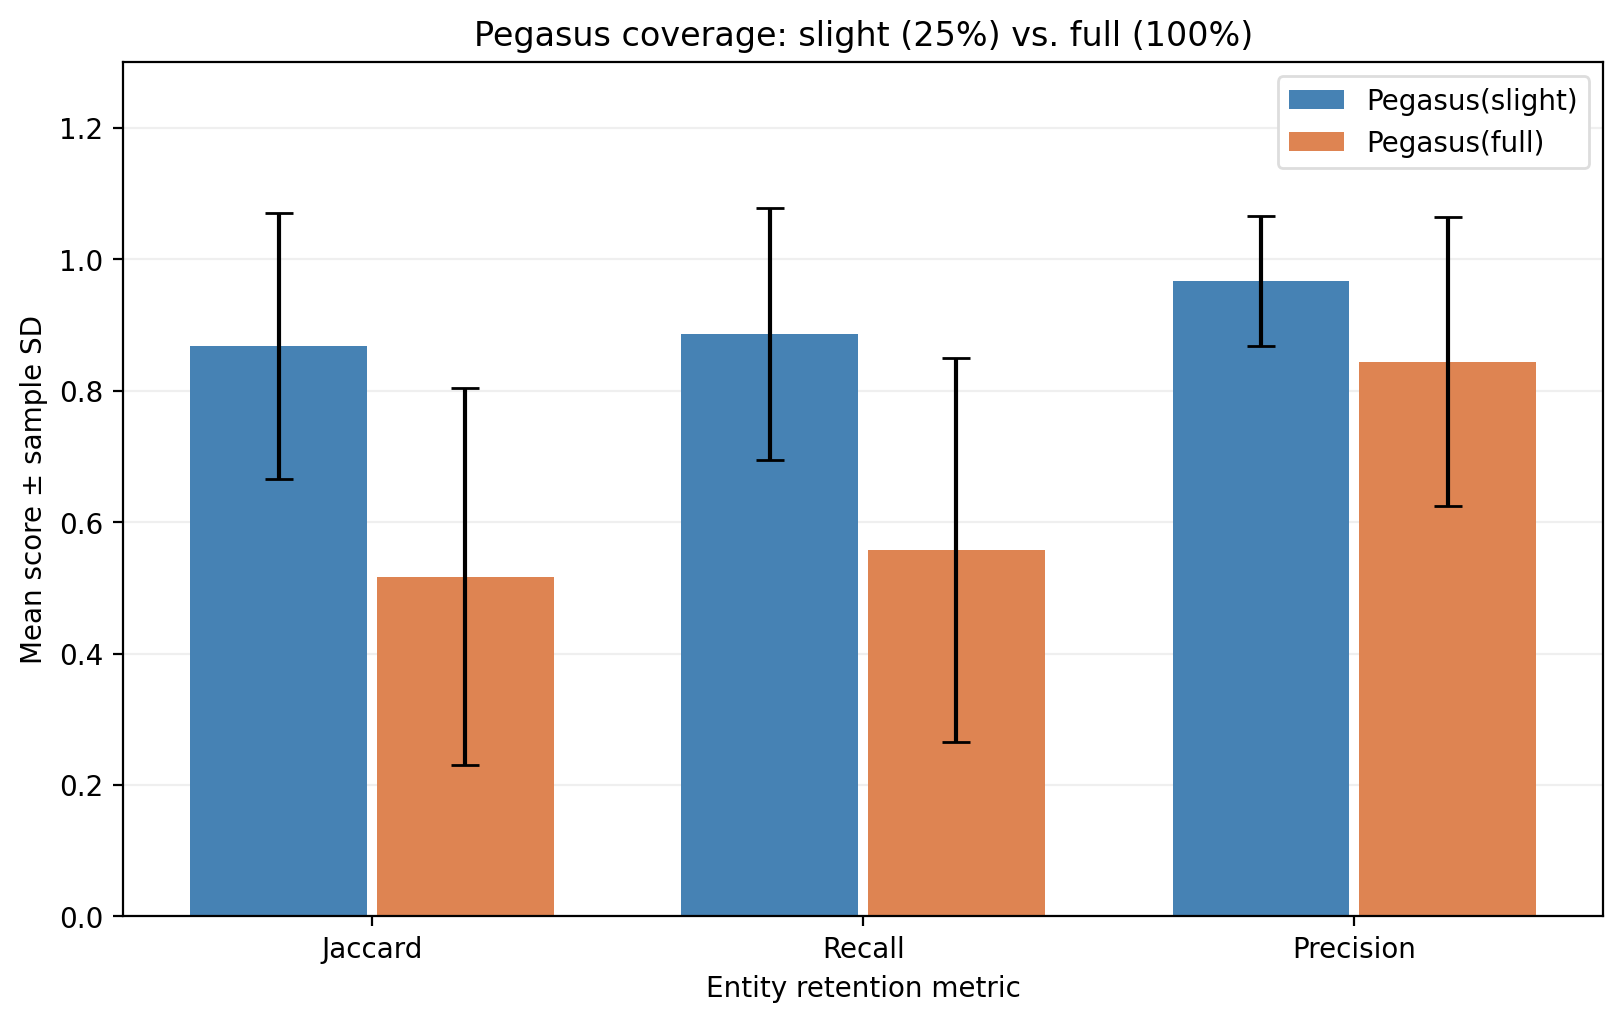

Results generated in data/results/task3_ner/.


In [18]:
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image

ner_pegasus = ner_scores[ner_scores.variant.isin(['Pegasus(slight)', 'Pegasus(full)'])]
ner_pegasus_wide = ner_pegasus.pivot(index=ner_ids, columns='variant', values=ner_metrics)
ner_pegasus_deltas = pd.DataFrame({
    metric: ner_pegasus_wide[(metric, 'Pegasus(full)')]
            - ner_pegasus_wide[(metric, 'Pegasus(slight)')]
    for metric in ner_metrics
}).reset_index()
ner_delta_summary = summarize_entity_scores(ner_pegasus_deltas, ['dataset'])
ner_pegasus_deltas.to_csv(ner_output / 'pegasus_article_deltas.csv', index=False)
ner_delta_summary.to_csv(ner_output / 'pegasus_full_minus_slight_summary.csv', index=False)

ner_means = ner_overall_summary.set_index('variant')
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
positions = np.arange(3)
for offset, variant, color in [(-.19, 'Pegasus(slight)', '#4682b4'), (.19, 'Pegasus(full)', '#de8452')]:
    row = ner_means.loc[variant]
    ax.bar(positions + offset, [row[metric + '_mean'] for metric in ner_metrics], width=.36,
           yerr=[row[metric + '_std'] for metric in ner_metrics], capsize=5,
           label=variant, color=color)
ax.set(xticks=positions, xticklabels=['Jaccard', 'Recall', 'Precision'],
       xlabel='Entity retention metric', ylabel='Mean score ± sample SD',
       title='Pegasus coverage: slight (25%) vs. full (100%)', ylim=(0, 1.30))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=.2)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=1, edgecolor='#dddddd')
ner_chart_buffer = BytesIO()
fig.savefig(ner_chart_buffer, format='png', dpi=200, bbox_inches='tight')
ner_chart_bytes = ner_chart_buffer.getvalue()
(ner_output / 'pegasus_ner_comparison.png').write_bytes(ner_chart_bytes)
display(Image(data=ner_chart_bytes))
plt.close(fig)

slight = ner_means.loc['Pegasus(slight)']
full = ner_means.loc['Pegasus(full)']
recall_gap = slight.recall_mean - full.recall_mean
precision_gap = slight.precision_mean - full.precision_mean
ner_dataset_means = ner_dataset_summary.set_index(['dataset', 'variant'])
ner_domain_gaps = {}
for dataset in sorted(ner_paired.dataset.unique()):
    ner_domain_gaps[dataset] = {
        metric: ner_dataset_means.loc[(dataset, 'Pegasus(slight)'), metric + '_mean']
                - ner_dataset_means.loc[(dataset, 'Pegasus(full)'), metric + '_mean']
        for metric in ['recall', 'precision']
    }
ner_consistent = sum(gap['recall'] > gap['precision'] for gap in ner_domain_gaps.values())
ner_interpretation = (
    f"Among {len(ner_paired) - ner_excluded:,} eligible article-source pairs, mean Jaccard was "
    f"{ner_means.loc['ChatGPT', 'jaccard_mean']:.3f} for ChatGPT, "
    f"{ner_means.loc['Dipper(high)', 'jaccard_mean']:.3f} for Dipper(high), "
    f"{slight.jaccard_mean:.3f} for Pegasus(slight), and {full.jaccard_mean:.3f} for Pegasus(full). "
    f"The Pegasus slight-to-full decline was larger for Recall ({recall_gap:.3f}) than "
    f"Precision ({precision_gap:.3f}), indicating more entity dropping than introduction of new entity strings. "
    f"This relationship held across {ner_consistent} of {len(ner_domain_gaps)} datasets, although its magnitude varied by domain: "
    f"Recall gaps were {ner_domain_gaps['sci_gen']['recall']:.3f} for scientific text, "
    f"{ner_domain_gaps['xsum']['recall']:.3f} for news, and {ner_domain_gaps['yelp']['recall']:.3f} for reviews. "
    "Thus, greater paraphrase coverage primarily affected entity retention. Exact-string differences can reflect "
    "aliases or NER errors rather than factual hallucinations. Dipper(high)'s low overlap warrants checking "
    "generation quality and upstream alignment."
)
assert 80 <= len(ner_interpretation.split()) <= 120
print('Results generated in data/results/task3_ner/.')


### Interpretation

Among 16,449 eligible article-source pairs, mean Jaccard was 0.551 for ChatGPT, 0.021 for Dipper(high), 0.868 for Pegasus(slight), and 0.517 for Pegasus(full). The Pegasus slight-to-full decline was larger for Recall (0.329) than Precision (0.122), indicating more entity dropping than introduction of new entity strings. This relationship held across 7 of 7 datasets, although its magnitude varied by domain: Recall gaps were 0.392 for scientific text, 0.292 for news, and 0.318 for reviews. Thus, greater paraphrase coverage primarily affected entity retention. Exact-string differences can reflect aliases or NER errors rather than factual hallucinations. Dipper(high)'s low overlap warrants checking generation quality and upstream alignment.

## Task 4 — Paraphraser Fingerprint Report

This section completes Person 4. We compare ChatGPT and Dipper(high) POS fingerprints, identify entity-retention winners from Task 3, and quantify Dipper(low) versus Dipper(high) intensity effects. Lower POS cosine means greater structural drift; lower NER Recall means more T0 entities were dropped.


In [19]:
task4_pos = dataset_summary.reset_index()
task4_ner = ner_overall_summary.copy()

assert paired["text_dipper_low"].map(lambda text: isinstance(text, str) and bool(text.strip())).all()
pos_dipper_low = extract_pos("text_dipper_low")
scores["dipper_low"] = row_cosine(pos_T0, pos_dipper_low)

eligible_ids = (
    ner_scores.loc[
        ner_scores["variant"].eq("ChatGPT") & ner_scores["n_original"].gt(0),
        ner_ids,
    ]
    .drop_duplicates()
)
task4_pos_common = scores.merge(eligible_ids, on=ner_ids, how="inner", validate="one_to_one")

low_texts = list(dict.fromkeys(ner_paired["text_dipper_low"]))
ner_nlp.max_length = max(ner_nlp.max_length, max(map(len, low_texts)) + 1)
low_entities = {
    text: {entity.text.strip().lower() for entity in doc.ents if entity.text.strip()}
    for text, doc in zip(
        low_texts,
        ner_nlp.pipe(low_texts, batch_size=64, n_process=NER_PROCESSES),
    )
}
low_recall_rows = []
for record in ner_paired.to_dict("records"):
    original = ner_entities[record["text_T0"]]
    low_recall_rows.append({
        **{key: record[key] for key in ner_ids},
        "ner_recall": entity_retention_metrics(
            original, low_entities[record["text_dipper_low"]]
        )["recall"],
    })
task4_low_ner = pd.DataFrame(low_recall_rows).merge(
    eligible_ids, on=ner_ids, how="inner", validate="one_to_one"
)
task4_high_ner = ner_scores.loc[
    ner_scores["variant"].eq("Dipper(high)"),
    ner_ids + ["recall"],
].rename(columns={"recall": "ner_recall"}).merge(
    eligible_ids, on=ner_ids, how="inner", validate="one_to_one"
)

task4_expected_count = len(eligible_ids)
if task4_expected_count == 0:
    raise ValueError("Task 4 has no eligible article-source pairs.")
assert len(task4_pos_common) == len(task4_low_ner) == len(task4_high_ner) == task4_expected_count
task4_intensity = pd.DataFrame([
    {
        "variant": "Dipper(low)",
        "pos_cosine_mean": task4_pos_common["dipper_low"].mean(),
        "pos_cosine_std": task4_pos_common["dipper_low"].std(),
        "ner_recall_mean": task4_low_ner["ner_recall"].mean(),
        "ner_recall_std": task4_low_ner["ner_recall"].std(),
        "count": len(task4_pos_common),
    },
    {
        "variant": "Dipper(high)",
        "pos_cosine_mean": task4_pos_common["dipper_high"].mean(),
        "pos_cosine_std": task4_pos_common["dipper_high"].std(),
        "ner_recall_mean": task4_high_ner["ner_recall"].mean(),
        "ner_recall_std": task4_high_ner["ner_recall"].std(),
        "count": len(task4_pos_common),
    },
])

task4_pos = task4_pos[task4_pos["paraphraser"].isin(["chatgpt", "dipper_high"])].pivot(
    index="dataset", columns="paraphraser", values="mean"
).reset_index()
task4_pos["higher_drift"] = task4_pos.apply(
    lambda row: "chatgpt" if row["chatgpt"] < row["dipper_high"] else "dipper_high",
    axis=1,
)
display(task4_pos)
display(task4_ner[task4_ner["variant"].isin(["ChatGPT", "Dipper(high)", "Pegasus(slight)"])])
display(task4_intensity)


text_dipper_low: 2,000/18,049
text_dipper_low: 4,000/18,049
text_dipper_low: 6,000/18,049
text_dipper_low: 8,000/18,049
text_dipper_low: 10,000/18,049
text_dipper_low: 12,000/18,049
text_dipper_low: 14,000/18,049
text_dipper_low: 16,000/18,049
text_dipper_low: 18,000/18,049
text_dipper_low: complete


paraphraser,dataset,chatgpt,dipper_high,higher_drift
0,cmv,0.971810,0.912892,dipper_high
1,eli5,0.959625,0.884229,dipper_high
2,sci_gen,0.977620,0.854403,dipper_high
3,tldr,0.974535,0.855715,dipper_high
4,wp,0.964965,0.927714,dipper_high
5,xsum,0.972107,0.859093,dipper_high
6,yelp,0.962805,0.881049,dipper_high


,variant,jaccard_count,jaccard_mean,jaccard_std,recall_count,recall_mean,recall_std,precision_count,precision_mean,precision_std
0,ChatGPT,16449,0.550686,0.301121,16449,0.629219,0.305531,15797,0.763750,0.256476
1,Dipper(high),16449,0.020715,0.063231,16449,0.036697,0.111853,14326,0.057806,0.144100
3,Pegasus(slight),16449,0.867891,0.202610,16449,0.886776,0.191986,16219,0.966965,0.099403


,variant,pos_cosine_mean,pos_cosine_std,ner_recall_mean,ner_recall_std,count
0,Dipper(low),0.984539,0.026992,0.648401,0.283203,16449
1,Dipper(high),0.881946,0.086388,0.036697,0.111853,16449


### 4a. Analytical report

#### Q1 — POS fingerprint

For POS drift, lower cosine similarity means a larger change in the normalized UPOS distribution. ChatGPT's overall cosine was 0.969, whereas Dipper(high)'s was 0.878. Dipper(high) had the lower cosine in all 7 datasets. In sci_gen, ChatGPT scored 0.978 versus 0.854 for Dipper(high), while in Yelp the values were 0.963 versus 0.881. With equal dataset weighting, Dipper(high) was 0.8913 for Human originals and 0.8808 for LLM originals; ChatGPT was 0.9745 and 0.9682, respectively. Thus, Dipper(high) produced stronger drift across domains, while source composition affected absolute similarity.

#### Q2 — Entity retention and introduction

Recall measures entity dropping, while Precision measures how much of the rewritten entity set is supported by T0. ChatGPT obtained Recall 0.629 and Precision 0.764; Dipper(high) obtained Recall 0.037 and Precision 0.058; Pegasus(slight) obtained Recall 0.887 and Precision 0.967. Dipper(high) is therefore the worst offender for both phenomena: it retains the fewest original entities and has the lowest proportion of supported rewritten entities. The two errors should remain conceptually separate, because low Recall indicates erasure whereas low Precision indicates newly introduced or unmatched entity strings. These exact-string scores can also reflect aliases or NER errors.

#### Q3 — Dipper intensity

Dipper(low) and Dipper(high) were compared on the same 16,449 article-source pairs with non-empty T0 entity sets. POS cosine decreased from 0.985 to 0.882, a gap of 0.103, whereas NER Recall decreased from 0.648 to 0.037, a much larger gap of 0.612. Thus content preservation, measured through entity Recall, was more sensitive to intensity than POS style. Increasing the Dipper dial sharply increased entity erasure in addition to grammatical drift. For RQ1, this suggests that semantic content planks can become fragile faster than the aggregate POS profile under stronger paraphrasing. Attribution experiments are still needed to identify the exact point of identity loss.
